# Лабораторная работа 1
Тема: движение человека в спорте.


## Данные

Тема корпуса - движение человека в спорте: оценка позы, биомеханика,
распознавание действий и оценка техники. Поиск выполнен через arXiv API
по 15 запросам за период 01.01.2020-05.10.2026.


In [18]:
import json
from pathlib import Path

SNAPSHOT_FILE = Path("arxiv_api_snapshot.json")
snapshot = None
if SNAPSHOT_FILE.exists():
    with SNAPSHOT_FILE.open(encoding="utf-8") as file:
        snapshot = json.load(file)
    print("сохранённых ответов:", len(snapshot["responses"]))


сохранённых ответов: 24


In [19]:
import hashlib
import re
import time
from collections import Counter
from itertools import combinations
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

API_URL = "https://export.arxiv.org/api/query"
DOWNLOAD_DATA = False
DATE_FROM = "2020-01-01"
DATE_TO = "2026-10-05"
SEED = 42

queries = [
    'all:"sports" AND all:"human motion"',
    'all:"sports" AND all:"pose estimation"',
    'all:"sports" AND all:"action recognition"',
    'all:"athlete" AND all:"motion"',
    'all:"sports" AND all:"human pose"',
    'all:"sports biomechanics"',
    'all:"athlete" AND all:"pose estimation"',
    'all:"sports" AND all:"motion capture"',
    'all:"sports" AND all:"motion analysis"',
    'all:"athlete" AND all:"biomechanics"',
    'all:"sport" AND all:"biomechanics"',
    'all:"athletic" AND all:"human motion"',
    'all:"sports" AND all:"kinematics"',
    'all:"sports" AND all:"movement analysis"',
    'all:"sports" AND all:"action quality assessment"',
]


def clean_text(text):
    text = re.sub(r"(?:https?://|www\.)\S+", " . ", str(text))
    text = re.sub(r"\$[^$]*\$", " . ", text)
    text = re.sub(r"\\(?:textbf|textit|emph)\{([^{}]*)\}", r"\1", text)
    return text


def add_publications(papers, body, expected_start):
    root = ET.fromstring(body)
    atom = "{http://www.w3.org/2005/Atom}"
    search = "{http://a9.com/-/spec/opensearch/1.1/}"
    total = root.findtext(f"{search}totalResults")
    start = root.findtext(f"{search}startIndex")
    if total is None or start is None:
        raise ValueError("в ответе API нет параметров страницы")
    total = int(total)
    if int(start) != expected_start:
        raise ValueError("API вернул другую страницу")
    entries = root.findall(f"{atom}entry")
    if expected_start + len(entries) > total or (not entries and expected_start < total):
        raise ValueError("API вернул неполную страницу")
    page_ids = set()
    for article in entries:
        def field(name):
            element = article.find(f"{atom}{name}")
            if element is None or not (element.text or "").strip():
                raise ValueError(f"в ответе API нет поля {name}")
            return " ".join(" ".join(element.itertext()).split())

        versioned_id = field("id").split("/abs/")[-1]
        arxiv_id = re.sub(r"v\d+$", "", versioned_id)
        if arxiv_id in page_ids:
            raise ValueError("API вернул повтор внутри страницы")
        page_ids.add(arxiv_id)
        match = re.search(r"v(\d+)$", versioned_id)
        authors = [" ".join(" ".join(a.itertext()).split())
                   for a in article.findall(f"{atom}author/{atom}name")]
        if not authors:
            raise ValueError("в ответе API нет авторов")
        row = {
            "arxiv_id": arxiv_id,
            "version": int(match.group(1)) if match else 1,
            "title": field("title"),
            "authors": ", ".join(authors),
            "abstract": field("summary"),
            "published": field("published")[:10],
            "url": f"https://arxiv.org/abs/{arxiv_id}",
        }
        if arxiv_id not in papers or row["version"] >= papers[arxiv_id]["version"]:
            papers[arxiv_id] = row
    return len(entries), total, page_ids


def collect_publications():
    papers = {}
    responses = []
    last_request = 0.0
    retry = Retry(total=4, backoff_factor=3,
                  status_forcelist=(429, 500, 502, 503, 504),
                  allowed_methods=frozenset(["GET"]), respect_retry_after_header=True)
    with requests.Session() as session:
        session.mount("https://", HTTPAdapter(max_retries=retry))
        session.headers.update({"User-Agent": "sports-motion-lab/1.0"})
        for query in queries:
            date_from = DATE_FROM.replace("-", "") + "0000"
            date_to = DATE_TO.replace("-", "") + "2359"
            dated_query = f"({query}) AND submittedDate:[{date_from} TO {date_to}]"
            start = 0
            expected_total = None
            query_ids = set()
            while True:
                time.sleep(max(0, 3.1 - (time.monotonic() - last_request)))
                params = {
                    "search_query": dated_query, "start": start, "max_results": 50,
                    "sortBy": "submittedDate", "sortOrder": "descending",
                }
                response = session.get(API_URL, params=params, timeout=90)
                last_request = time.monotonic()
                response.raise_for_status()
                body = response.content
                count, total, page_ids = add_publications(papers, body, start)
                if expected_total is not None and total != expected_total:
                    raise ValueError("число результатов изменилось во время загрузки")
                expected_total = total
                if query_ids & page_ids:
                    raise ValueError("API повторил статьи на соседних страницах")
                query_ids.update(page_ids)
                responses.append({
                    "url": response.url, "params": params,
                    "sha256": hashlib.sha256(body).hexdigest(),
                    "body": body.decode("utf-8"),
                })
                start += count
                if start == total:
                    if len(query_ids) != total:
                        raise ValueError("загружены не все статьи запроса")
                    break
    temporary = SNAPSHOT_FILE.with_suffix(".tmp")
    temporary.write_text(json.dumps({
        "date_from": DATE_FROM, "date_to": DATE_TO, "responses": responses,
    }, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    temporary.replace(SNAPSHOT_FILE)
    return pd.DataFrame(papers.values())


if DOWNLOAD_DATA:
    df_raw = collect_publications()
else:
    if snapshot is None:
        raise FileNotFoundError("нет arxiv_api_snapshot.json; для загрузки задайте DOWNLOAD_DATA = True")
    assert (snapshot["date_from"], snapshot["date_to"]) == (DATE_FROM, DATE_TO)
    papers = {}
    coverage = {}
    date_from = DATE_FROM.replace("-", "") + "0000"
    date_to = DATE_TO.replace("-", "") + "2359"
    expected_queries = {f"({query}) AND submittedDate:[{date_from} TO {date_to}]" for query in queries}
    for response in snapshot["responses"]:
        body = response["body"].encode("utf-8")
        assert hashlib.sha256(body).hexdigest() == response["sha256"]
        params = response["params"]
        count, total, page_ids = add_publications(papers, body, int(params["start"]))
        assert count <= int(params["max_results"])
        info = coverage.setdefault(params["search_query"], {"total": total, "pages": [], "ids": set()})
        assert info["total"] == total and not (info["ids"] & page_ids)
        info["ids"].update(page_ids)
        info["pages"].append((int(params["start"]), count))
    assert set(coverage) == expected_queries
    for query, info in coverage.items():
        pages = sorted(info["pages"])
        assert pages[0][0] == 0
        assert all(pages[i + 1][0] == pages[i][0] + pages[i][1]
                   for i in range(len(pages) - 1))
        assert sum(count for _, count in pages) == len(info["ids"]) == info["total"], query
    df_raw = pd.DataFrame(papers.values())

sport_terms = [
    "sport", "sports", "athlete", "athletic", "football", "soccer", "basketball",
    "tennis", "badminton", "volleyball", "baseball", "swimming", "runner", "running",
    "cycling", "gymnastics", "diving", "skating", "skiing", "boxing", "golf", "olympic",
]
motion_terms = [
    "human motion", "human movement", "human pose", "pose estimation", "motion capture",
    "motion analysis", "movement analysis", "action recognition", "action quality",
    "biomechanics", "biomechanical", "kinematics", "kinematic", "kinetics", "joint angle",
    "body movement", "motion prediction", "motion tracking", "trajectory", "center of mass",
    "jump", "jumping", "gait", "posture", "body orientation", "movement pattern",
    "technique analysis",
]

sport_terms += [
    "judo", "karate", "handball", "bowling", "canoe", "rowing", "fencing", "parkour",
    "yoga", "dance", "dancing", "sportsmen", "skier", "skiers", "weight training",
    "cricket", "darts", "climbing", "hammer throw", "taekwondo", "squat",
]
motion_terms += [
    "motion", "movement", "tracking", "pose", "kinematical", "joint loading",
    "technique", "stroke", "kinematic", "gait", "body orientation",
]


def term_pattern(terms):
    alternatives = [re.escape(term).replace(r"\ ", r"[\s-]+") for term in terms]
    return re.compile(r"(?<![a-z])(?:" + "|".join(alternatives) + r")(?![a-z])", re.I)


sport_pattern = term_pattern(sport_terms)
motion_pattern = term_pattern(motion_terms)


def is_relevant(row):
    text = f"{row['title']} {row['abstract']}"
    return bool(sport_pattern.search(text) and motion_pattern.search(text))


excluded_papers = {
    "2302.06108",
    "2408.01655",
    "2510.12749",
    "2008.11672",
    "2307.14889",
    "2404.10383",
    "2401.17320",
    "2311.12300",
    "2211.09310",
    "2111.00629",
    "2412.12878",
    "2003.14109",
    "2606.31979",
    "2503.19104",
    "2607.24611",
    "2502.12558",
    "2010.00411",
    "2005.12661",
    "2603.25135",
    "2607.14809",
    "2108.07329",
    "2404.08504",
    "2502.09460",
    "2404.10212",
    "2406.15649",
    "2006.11620",
    "2503.14760",
    "2607.15463",
    "2606.09246",
    "2604.13581",
    "2601.14037",
    "2510.02264",
    "2502.17244",
    "2507.14368",
    "2508.13303",
    "2012.00873",
    "2210.04514",
    "2111.01029",
    "2201.02503",
    "2603.18354",
    "2605.01540",
    "2604.15665",
    "2606.30266",
    "2511.06140",
    "2509.23455",
    "2503.15225",
    "2409.01947",
    "2404.08401",
    "2408.11836",
}

topic_mask = df_raw.apply(is_relevant, axis=1)
excluded_mask = df_raw["arxiv_id"].isin(excluded_papers)
df = df_raw[topic_mask & ~excluded_mask].copy()
df["published"] = pd.to_datetime(df["published"], errors="raise")
df = df[df["published"].between(DATE_FROM, DATE_TO)]
df = df.sort_values(["published", "title"], ascending=[False, True]).reset_index(drop=True)

required = ["title", "authors", "abstract", "published"]
blank_counts = {column: int(df[column].fillna("").astype(str).str.strip().eq("").sum())
                for column in required[:-1]}
assert len(df) >= 300
assert df["published"].dt.year.min() >= 2020
assert not any(blank_counts.values())
assert df["arxiv_id"].is_unique
assert df["url"].str.startswith("https://arxiv.org/abs/").all()

print("до отбора:", len(df_raw), "| после:", len(df))
print("период:", df["published"].min().date(), "-", df["published"].max().date())
df[["arxiv_id", "title", "authors", "abstract"]].head(3)

до отбора: 380 | после: 326
период: 2020-01-02 - 2026-10-02


,arxiv_id,title,authors,abstract
0,2610.03388,KungfuAthleteBot: learning high-dynamic humano...,"Zhongxiang Lei, Lulu Cao, Xuyang Wang, Tianyi ...","Video is an abundant, inexpensive source of hu..."
1,2609.39300,BMASH: Ball-Motion-Aware Soccer Header Spotting,"Ahmed Endris Hasen, Muhammad Shahzad Khan, Nik...",Recent advances in computer vision have made b...
2,2609.31840,Humanoid Badminton: Learning Dynamic Racket Sk...,"Jingzhi Cui, Zhexiong Wang, Bangjie Xu, Pengyu...",High-speed racket sports provide a demanding t...


включены спортивные исследования, анализ техники и травм, спортивная реабилитация
и воспроизведение спортивных движений роботами. Общие методы оценки позы оставлены,
если они проверены на наборах со спортивными действиями. Одного упоминания спорта
как возможного применения недостаточно. Пограничные случаи проверены по названиям и аннотациям.
Это выборка по запросам, а не полная статистика arXiv.


## Разведочный анализ

Показаны число публикаций по годам, длина аннотаций и частоты слов.

2026 год неполный: данные собраны до 5 октября.


статей в выборке за 2020-2025: +211.5%
аннотации: медиана 185 слов; у половины от 160 до 217


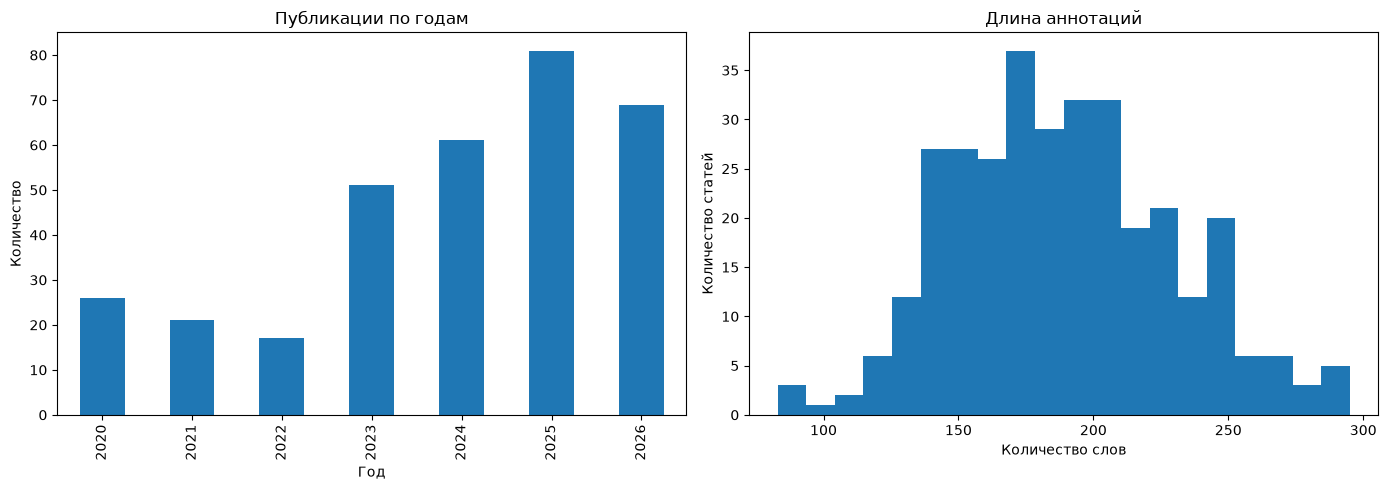

In [20]:
df["year"] = df["published"].dt.year
df["abstract_length"] = df["abstract"].str.split().str.len()

year_counts = df["year"].value_counts().sort_index()
complete_years = year_counts[year_counts.index < df["published"].max().year]
if len(complete_years) >= 2:
    first_year, last_year = complete_years.index[0], complete_years.index[-1]
    change = 100 * (complete_years.iloc[-1] / complete_years.iloc[0] - 1)
    print(f"статей в выборке за {first_year}-{last_year}: {change:+.1f}%")
q1, median, q3 = df["abstract_length"].quantile([0.25, 0.50, 0.75])
print(f"аннотации: медиана {median:.0f} слов; у половины от {q1:.0f} до {q3:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df["year"].value_counts().sort_index().plot.bar(ax=axes[0], title="Публикации по годам")
df["abstract_length"].plot.hist(bins=20, ax=axes[1], title="Длина аннотаций")
axes[0].set_xlabel("Год")
axes[0].set_ylabel("Количество")
axes[1].set_xlabel("Количество слов")
axes[1].set_ylabel("Количество статей")
plt.tight_layout()
plt.show()

уникальных слов: 5535


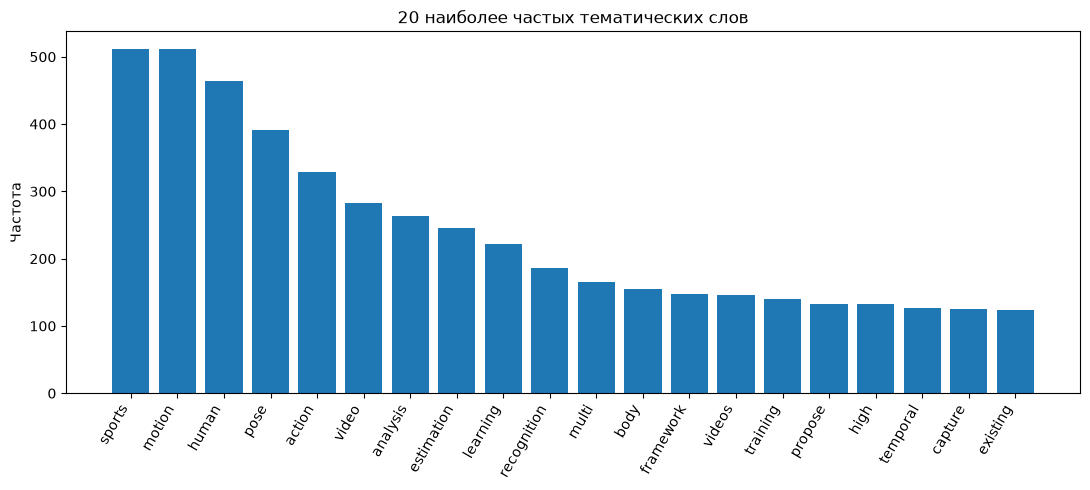

In [21]:
import nltk
from nltk.corpus import stopwords

try:
    stopwords.words("english")
except LookupError:
    if not nltk.download("stopwords", quiet=True):
        raise RuntimeError("Не удалось загрузить английские стоп-слова NLTK")

eda_stop_words = set(stopwords.words("english"))


def tokenize_for_eda(text):
    tokens = re.findall(r"\b[a-z]+\b", clean_text(text).lower())
    return [token for token in tokens if len(token) > 2 and token not in eda_stop_words]


all_words = []
zipf_words = []
for text in df["title"] + " . " + df["abstract"]:
    all_words.extend(tokenize_for_eda(text))
    zipf_words.extend(re.findall(r"\b[a-z]+\b", clean_text(text).lower()))

eda_generic = {"data", "based", "model", "models", "using", "method", "methods", "performance", "dataset", "datasets", "result", "results", "paper", "study", "work", "approach", "system", "real", "time"}
word_counts = Counter(word for word in all_words if word not in eda_generic)
top_words = word_counts.most_common(20)
print("уникальных слов:", len(word_counts))

plt.figure(figsize=(11, 5))
plt.bar([word for word, _ in top_words], [count for _, count in top_words])
plt.xticks(rotation=60, ha="right")
plt.title("20 наиболее частых тематических слов")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

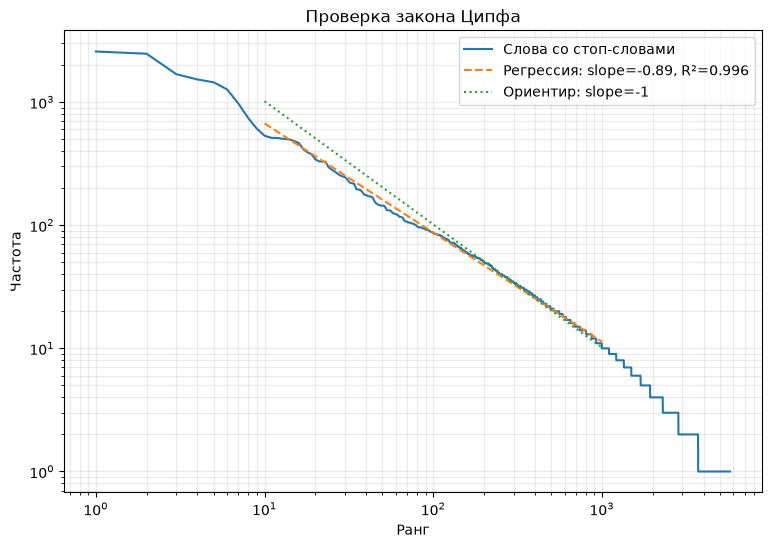

In [22]:
zipf_counts = Counter(zipf_words)
frequencies = np.array(sorted(zipf_counts.values(), reverse=True), dtype=float)
ranks = np.arange(1, len(frequencies) + 1, dtype=float)

fit_mask = (ranks >= 10) & (ranks <= 1000) & (frequencies >= 5)
x = np.log10(ranks[fit_mask])
y = np.log10(frequencies[fit_mask])
slope, intercept = np.polyfit(x, y, 1)
predicted_log = slope * x + intercept
r_squared = 1 - np.sum((y - predicted_log) ** 2) / np.sum((y - y.mean()) ** 2)
fitted = 10 ** intercept * ranks ** slope
ideal_scale = 10 ** np.mean(y + x)
ideal = ideal_scale / ranks

plt.figure(figsize=(9, 6))
plt.loglog(ranks, frequencies, label="Слова со стоп-словами")
plt.loglog(ranks[fit_mask], fitted[fit_mask], "--",
           label=f"Регрессия: slope={slope:.2f}, R²={r_squared:.3f}")
plt.loglog(ranks[fit_mask], ideal[fit_mask], ":", label="Ориентир: slope=-1")
plt.xlabel("Ранг")
plt.ylabel("Частота")
plt.title("Проверка закона Ципфа")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.show()

проверялся только участок с рангами 10-1000. Наклон равен -0,886,
R² = 0,996. Частоты на этом участке близки к закону Ципфа.


## Ключевые слова

Заголовки и аннотации очищаются и лемматизируются. Сохраняются `2D` и `3D`.
TF-IDF оценивает фразы, сокращения объединяются с полными названиями.


In [23]:
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

for resource, package in [
    ("corpora/wordnet", "wordnet"),
    ("taggers/averaged_perceptron_tagger_eng", "averaged_perceptron_tagger_eng"),
]:
    try:
        nltk.data.find(resource)
    except LookupError:
        try:
            nltk.data.find(resource + ".zip")
        except LookupError:
            if not nltk.download(package, quiet=True):
                raise RuntimeError(f"не удалось загрузить {package}")

extra_stop_words = {
    "based", "using", "use", "used", "method", "methods", "model", "models",
    "approach", "approaches", "result", "results", "paper", "study", "work",
    "propose", "proposed", "show", "shows", "new", "novel", "provide", "provides",
    "performance", "data", "dataset", "datasets", "system", "systems", "task", "tasks",
    "real", "different", "existing", "experiment", "experiments", "experimental",
    "however", "input", "output", "end", "textbf", "even", "also", "may", "one", "two",
    "across", "within", "without", "via", "et", "al", "towards", "respect",
    "challenge", "opportunity", "methodology", "reward", "highly", "achieve",
    "achieves", "achieving", "valuable", "significant", "comprehensive", "various",
    "absolute", "class", "survey", "review", "algorithm", "algorithms", "strong",
    "baseline", "future", "research", "first", "scale", "net", "instance", "case",
    "contains", "contain", "format", "important", "role", "technology", "specific",
    "solution", "mode", "detailed", "self", "room", "way", "aspect", "kind",
    "comprise", "comprising", "facilitate", "facilitates", "enforce", "enforces",
    "demonstrate", "demonstrates", "demonstrating", "enable", "enables", "enabling",
    "introduce", "introduces", "present", "presented", "presenting", "aim", "aims",
    "fine", "sub", "entry", "item", "insight", "community", "href", "url",
    "twenty", "thirty", "forty", "fifty", "hundred", "thousand",
}
keyword_stop_words = set(stopwords.words("english")) | extra_stop_words
lemmatizer = WordNetLemmatizer()
activity_nouns = {
    "running", "walking", "swimming", "skiing", "skating", "boxing", "climbing",
    "jumping", "rowing", "cycling", "diving", "wrestling", "fencing",
}


def normalize_text(text):
    text = re.sub(r"\bstate[\s-]+of[\s-]+the[\s-]+art\b", " . ", clean_text(text), flags=re.I)
    raw_tokens = re.findall(r"\d+d\b|[a-z]+|[.!?;,:()\[\]/]", text.lower().replace("-", " "))
    words = [token for token in raw_tokens if token.isalpha() or re.fullmatch(r"\d+d", token)]
    tagged_words = iter(pos_tag(words))
    normalized = []
    for token in raw_tokens:
        if not token.isalpha() and not re.fullmatch(r"\d+d", token):
            normalized.append(None)
            continue
        token, tag = next(tagged_words)
        if re.fullmatch(r"\d+d", token):
            normalized.append((token, "J"))
            continue
        if len(token) <= 2 or token in keyword_stop_words:
            normalized.append(None)
            continue
        if token in activity_nouns:
            lemma, part = token, "N"
        elif tag.startswith("N"):
            lemma, part = lemmatizer.lemmatize(token, wordnet.NOUN), "N"
        elif tag.startswith("J"):
            lemma, part = lemmatizer.lemmatize(token, wordnet.ADJ), "J"
        else:
            normalized.append(None)
            continue
        normalized.append((lemma, part) if lemma not in keyword_stop_words else None)
    return normalized


df["text"] = df["title"] + " " + df["abstract"]
df["normalized_title"] = df["title"].map(normalize_text)
df["normalized_abstract"] = df["abstract"].map(normalize_text)
df["normalized_text"] = [
    title + [None] + title + [None] + abstract
    for title, abstract in zip(df["normalized_title"], df["normalized_abstract"])
]

weak_boundary_words = {
    "application", "framework", "problem", "process", "dynamic", "simple",
    "general", "effective", "possible", "several", "potential", "reliable",
}
weak_phrases = {
    "research topic", "natural condition", "little attention", "recent advance",
    "known temporal boundary", "high cost", "high rate", "wide range",
    "diverse range", "world scenario", "test set", "daily life",
    "implementation code", "comparative analysis", "learning scheme",
    "challenging scenario", "high quality", "valuable resource",
}
aliases = {
    "aqa": "action quality assessment",
    "imu": "inertial measurement unit",
    "cnn": "convolutional neural network",
    "har": "human activity recognition",
    "grf": "ground reaction force",
    "hmr": "human mesh recovery",
    "vlm": "vision language model",
    "vlms": "vision language model",
    "lstm": "long short term memory",
    "hpe": "human pose estimation",
}
expanded_aliases = set(aliases.values())


def phrase_candidates(tokens):
    candidates = []
    for size in range(1, 5):
        for start in range(len(tokens) - size + 1):
            window = tokens[start:start + size]
            if any(token is None for token in window):
                continue
            words, parts = zip(*window)
            if len(set(words)) != size or parts[-1] != "N":
                continue
            if words[0] in weak_boundary_words or words[-1] in weak_boundary_words:
                continue
            phrase = " ".join(words)
            if phrase in weak_phrases or (size == 4 and phrase not in expanded_aliases):
                continue
            candidates.append(aliases.get(phrase, phrase))
    return candidates


vectorizer = TfidfVectorizer(
    analyzer=phrase_candidates,
    min_df=2,
    max_df=0.70,
    sublinear_tf=True,
)
tfidf_matrix = vectorizer.fit_transform(df["normalized_text"])
terms = vectorizer.get_feature_names_out()


def is_subphrase(first, second):
    first_words, second_words = first.split(), second.split()
    return any(second_words[start:start + len(first_words)] == first_words
               for start in range(len(second_words) - len(first_words) + 1))


sport_keyword_patterns = {name: term_pattern(variants) for name, variants in {
    "table tennis": ["table tennis"],
    "tennis": ["tennis"],
    "badminton": ["badminton"],
    "soccer": ["soccer"],
    "american football": ["american football", "ncaa football"],
    "basketball": ["basketball"],
    "baseball": ["baseball"],
    "running": ["running", "runner", "runners", "sprint", "sprinting"],
    "swimming": ["swimming", "swim", "swimmer"],
    "diving": ["diving"],
    "figure skating": ["figure skating"],
    "skating": ["skating", "skater", "skaters"],
    "skiing": ["skiing", "ski", "skier", "skiers"],
    "gymnastics": ["gymnastics", "gymnast"],
    "boxing": ["boxing"],
    "golf": ["golf"],
    "rugby": ["rugby"],
    "judo": ["judo"],
    "taekwondo": ["taekwondo"],
    "climbing": ["climbing"],
    "fencing": ["fencing", "fencer"],
    "canoe": ["canoe", "canoeing"],
    "rowing": ["rowing"],
    "cycling": ["cycling"],
    "bowling": ["bowling"],
    "cricket": ["cricket"],
    "archery": ["archery"],
    "yoga": ["yoga"],
    "parkour": ["parkour"],
}.items()}


def sport_keywords(title):
    selected = []
    for name, pattern in sport_keyword_patterns.items():
        if pattern.search(title) and not any(is_subphrase(name, other) for other in selected):
            selected.append(name)
    other_sprints = {"canoe", "rowing", "swimming", "skiing", "skating", "cycling"}
    if "running" in selected and other_sprints.intersection(selected):
        if not re.search(r"\b(?:running|runner|runners)\b", title, re.I):
            selected.remove("running")
    return selected


def get_keywords(row, title, top_n=10):
    scores = row.toarray().ravel()
    ranked = sorted(
        ((scores[index] * (1 + 0.35 * (len(terms[index].split()) - 1)), terms[index])
         for index in np.flatnonzero(scores)),
        reverse=True,
    )
    if not ranked:
        return []
    minimum = max(0.05, 0.40 * ranked[0][0])
    selected = sport_keywords(title)
    for score, term in ranked:
        if score < minimum and len(selected) >= 3:
            break
        if any(is_subphrase(term, other) or is_subphrase(other, term) for other in selected):
            continue
        selected.append(term)
        if len(selected) == top_n:
            break
    return selected


df["keywords"] = [get_keywords(tfidf_matrix[i], df.at[i, "title"]) for i in range(len(df))]
ngram_counts = Counter(len(keyword.split()) for keywords in df["keywords"] for keyword in keywords)
ngram_names = {1: "униграммы", 2: "биграммы", 3: "триграммы", 4: "4-граммы"}

print("тегов на статью:", df["keywords"].map(len).min(), "-", df["keywords"].map(len).max(),
      "| в среднем:", round(df["keywords"].map(len).mean(), 2))
print("фразы:", {ngram_names.get(size, f"{size}-граммы"): count
                  for size, count in sorted(ngram_counts.items())})
assert df["keywords"].map(bool).all()
assert sum(ngram_counts.values()) == df["keywords"].map(len).sum()
df[["arxiv_id", "title", "authors", "abstract", "published", "url", "keywords"]].assign(
    keywords=lambda table: table["keywords"].map(lambda words: "; ".join(words))
).to_csv("publications.csv", index=False)
print("результат: publications.csv")


тегов на статью: 3 - 10 | в среднем: 8.81
фразы: {'униграммы': 1158, 'биграммы': 1333, 'триграммы': 376, '4-граммы': 4}
результат: publications.csv


фразы не пересекают границы предложений и удалённых слов. Часть речи определяется
по предложению, в котором стоит слово. Заголовок повторяется дважды; `min_df=2` убирает единичные фразы,
`max_df=0.7` убирает слишком общие. Параметры выбраны вручную.
Вид спорта из заголовка сохраняется отдельным тегом, чтобы
не терялся при отборе TF-IDF. Четырёхсловные названия вроде `long short term memory` тоже учтены.


## Граф ключевых слов

Ключевые слова связаны, если встречаются в одной публикации. Вес ребра равен
числу таких публикаций.


In [24]:
G = nx.Graph()

for keywords in df["keywords"]:
    unique_keywords = sorted(set(keywords))
    G.add_nodes_from(unique_keywords)
    for first, second in combinations(unique_keywords, 2):
        if G.has_edge(first, second):
            G[first][second]["weight"] += 1
        else:
            G.add_edge(first, second, weight=1)

print("вершин:", G.number_of_nodes())
print("рёбер:", G.number_of_edges())
print("компонент:", nx.number_connected_components(G))
print("плотность:", round(nx.density(G), 5))
edge_weights = np.array([data["weight"] for _, _, data in G.edges(data=True)])
single_edges_share = 100 * np.mean(edge_weights == 1)
print(f"рёбра веса 1: {single_edges_share:.1f}%")
print("сильнейшие связи:")
for first, second, data in sorted(G.edges(data=True), key=lambda edge: edge[2]["weight"], reverse=True)[:10]:
    print(first, "-", second, "| вес:", data["weight"])

вершин: 1489
рёбер: 11548
компонент: 1
плотность: 0.01042
рёбра веса 1: 97.6%
сильнейшие связи:
soccer - broadcast video | вес: 4
human pose estimation - joint position error | вес: 4
human pose estimation - multi view | вес: 4
action quality assessment - score | вес: 4
ball - table tennis | вес: 3
skill - imitation | вес: 3
human pose estimation - 3d human pose | вес: 3
multi view - human mesh recovery | вес: 3
action quality assessment - modality | вес: 3
running - sprint | вес: 3


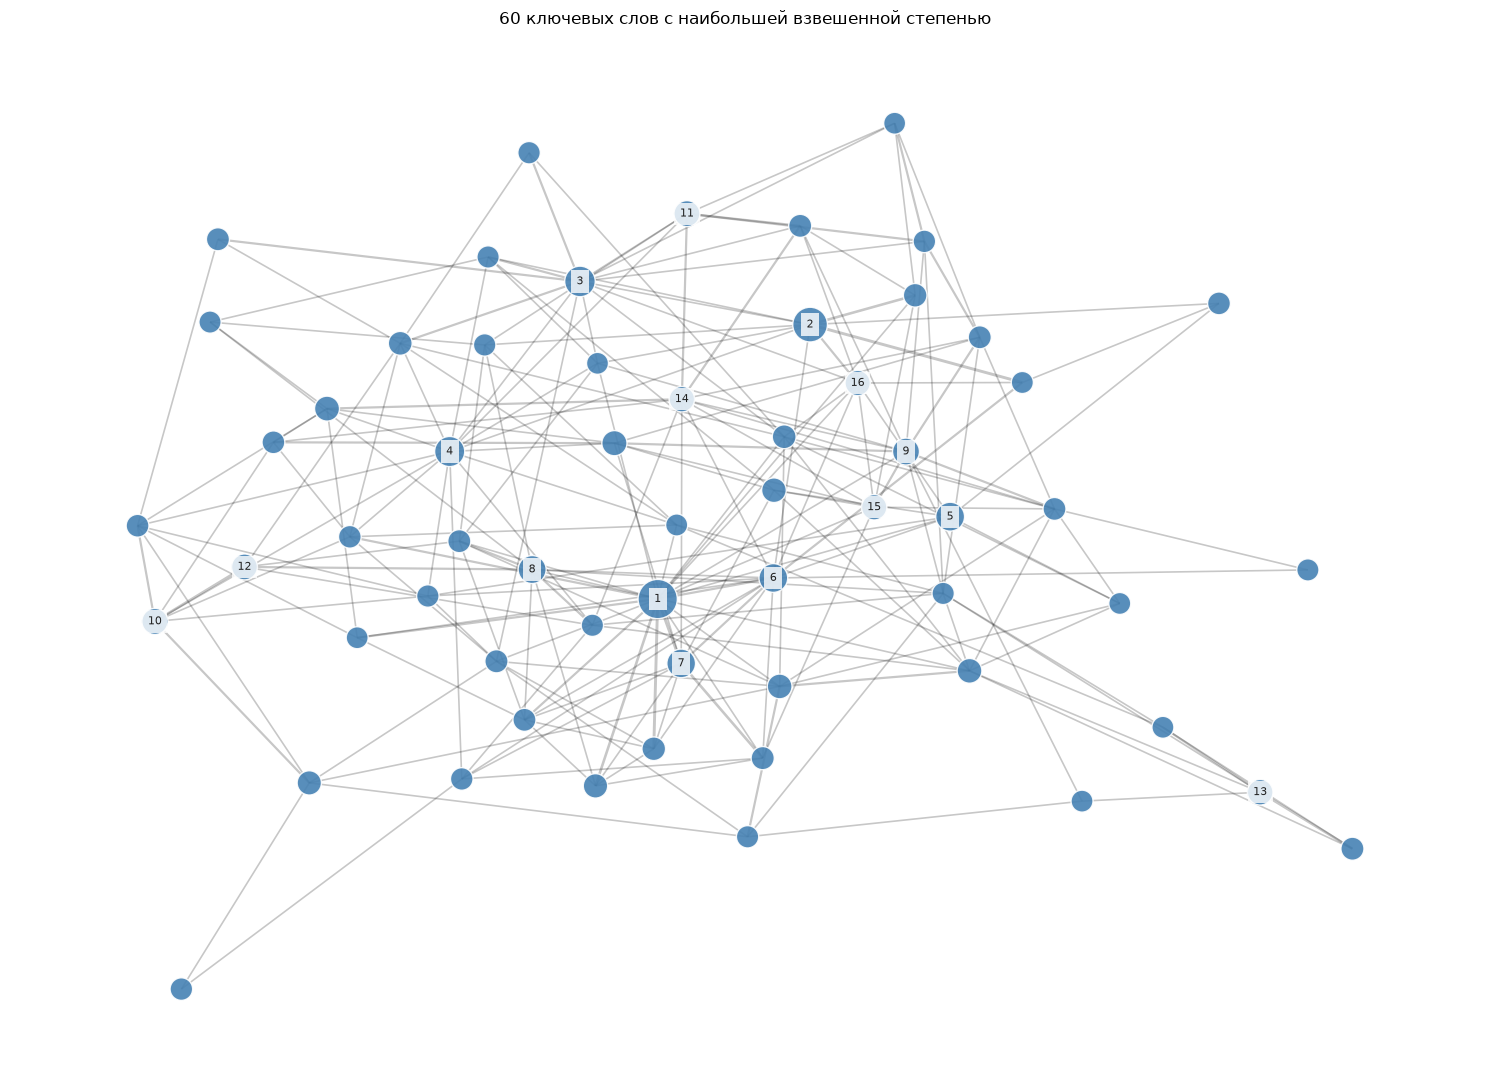

обозначения:
 1 | human pose estimation
 2 | action quality assessment
 3 | running
 4 | action recognition
 5 | inertial measurement unit
 6 | 3d pose estimation
 7 | multi view
 8 | soccer
 9 | skill
10 | table tennis
11 | machine learning
12 | ball
13 | head impact
14 | tennis
15 | human motion
16 | exercise


In [25]:
weighted_degree = dict(G.degree(weight="weight"))
visible_nodes = sorted(G, key=lambda node: (-weighted_degree[node], node))[:60]
G_visible = G.subgraph(visible_nodes).copy()
visible_components = sorted(nx.connected_components(G_visible), key=lambda group: (-len(group), min(group)))
main_visible = G_visible.subgraph(visible_components[0]).copy()
position = nx.spring_layout(main_visible, seed=SEED, weight="weight", k=0.6, iterations=150)
outside = sorted(set(G_visible) - set(main_visible))
label_numbers = {node: str(index) for index, node in enumerate(visible_nodes[:16], 1)}
for index, node in enumerate(outside):
    position[node] = np.array([1.25, 1 - 2 * index / max(1, len(outside) - 1)])


def draw_keyword_graph(cluster_by_node=None):
    from matplotlib.patches import Patch
    fig, ax = plt.subplots(figsize=(15, 11))
    cluster_ids = sorted({cluster_by_node[node] for node in G_visible}) if cluster_by_node else []
    palette = plt.get_cmap("tab20", max(1, len(cluster_ids)))
    colors = {cluster: palette(index) for index, cluster in enumerate(cluster_ids)}
    maximum = max(weighted_degree.values())
    nx.draw_networkx_nodes(
        G_visible, position, ax=ax,
        node_color=[colors[cluster_by_node[node]] if cluster_by_node else "#4682b4"
                    for node in G_visible],
        node_size=[150 + 650 * weighted_degree[node] / maximum for node in G_visible],
        edgecolors="white", alpha=0.9,
    )
    nx.draw_networkx_edges(G_visible, position, ax=ax, alpha=0.22,
                           width=[0.5 + np.log1p(G_visible[u][v]["weight"])
                                  for u, v in G_visible.edges()])
    nx.draw_networkx_labels(G_visible, position, labels=label_numbers, ax=ax,
                            font_size=8, font_color="#202020",
                            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8})
    ax.set_title("Кластеры ключевых слов" if cluster_by_node else
                 "60 ключевых слов с наибольшей взвешенной степенью")
    if cluster_by_node:
        ax.legend(handles=[Patch(color=colors[c], label=str(c + 1)) for c in cluster_ids],
                  title="Номер кластера", loc="upper left", bbox_to_anchor=(1, 1), ncol=2)
    ax.axis("off")
    fig.tight_layout()
    plt.show()


draw_keyword_graph()
print("обозначения:")
for term, number in label_numbers.items():
    print(f"{number:>2} | {term}")

показаны 60 вершин с наибольшей взвешенной степенью. Размер узла зависит
от суммы весов связей. Метрики рассчитаны по полному графу.


## Сообщества ключевых слов

Сообщества найдены алгоритмом Louvain. Показана модулярность.
Алгоритм запущен пять раз с разными seed, чтобы сравнить состав групп.


кластеров: 20
модулярность: 0.53
по 5 seed: Q=0.531 ± 0.001
средний ARI: 0.352


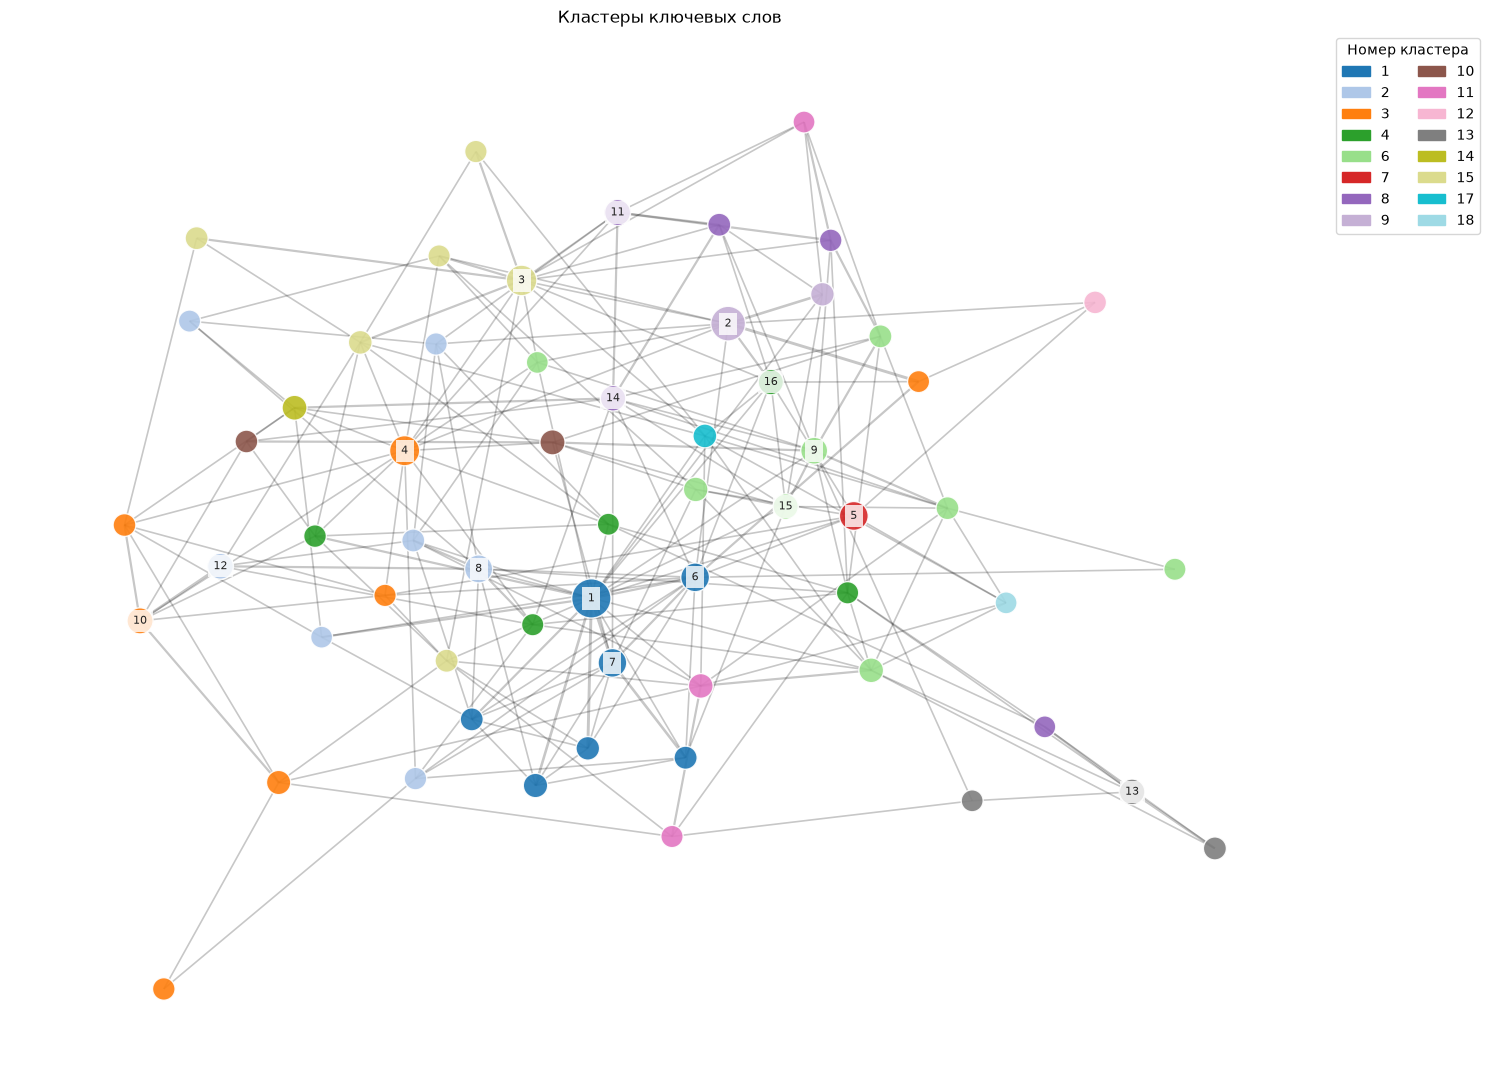

крупнейшие сообщества:
 1. 140 терминов: human pose estimation, 3d pose estimation, multi view, 3d human pose, joint position error, human mesh recovery, transformer, rotation
    пример: KASportsFormer: Kinematic Anatomy Enhanced Transformer for 3D Human Pose Estimation on Short Sports Scene Video | теги группы: 3d pose estimation, anatomy, human pose estimation, kinematic motion, motion information, short video, sport pose, sport scene, transformer
 2. 123 терминов: soccer, ball, event, basketball, human action recognition, human activity recognition, feature representation, sport activity
    пример: Vector field theory in motion: Revealing latent potentials in soccer dynamics | теги группы: ball, competitive environment, field, player movement, season, soccer, team, theory, top level, vector
 3. 111 терминов: action recognition, table tennis, sport video, classification, sport action recognition, figure skating, score, human robot interaction
    пример: Sport Task: Fine Grained Ac

In [26]:
communities = nx.community.louvain_communities(G, weight="weight", seed=SEED)
communities = sorted(communities, key=lambda group: (-len(group), min(group)))
modularity = nx.community.modularity(G, communities, weight="weight")
node_cluster = {node: index for index, community in enumerate(communities) for node in community}

print("кластеров:", len(communities))
print("модулярность:", round(modularity, 3))

from sklearn.metrics import adjusted_rand_score

seeds = [7, 21, 42, 73, 101]
partitions = []
seed_modularities = []
node_order = list(G.nodes)
for seed in seeds:
    partition = nx.community.louvain_communities(G, weight="weight", seed=seed)
    labels = {node: label for label, group in enumerate(partition) for node in group}
    partitions.append([labels[node] for node in node_order])
    seed_modularities.append(nx.community.modularity(G, partition, weight="weight"))
stability = [
    adjusted_rand_score(partitions[i], partitions[j])
    for i, j in combinations(range(len(seeds)), 2)
]
print(f"по 5 seed: Q={np.mean(seed_modularities):.3f} ± {np.std(seed_modularities):.3f}")
print(f"средний ARI: {np.mean(stability):.3f}")

draw_keyword_graph(node_cluster)

print("крупнейшие сообщества:")
representatives = {
    "human pose estimation": "2507.20763",
    "action quality assessment": "2301.06103",
    "exercise": "2311.00401",
    "markerless motion capture": "2409.10175",
    "sport video": "2301.13576",
    "head impact": "2502.15405",
    "wearable device": "2608.25126",
    "physic": "2507.01340",
    "inertial measurement unit": "2402.09459",
    "instruction": "2405.18565",
}
for index, community in enumerate(communities[:10], 1):
    top_terms = sorted(community, key=lambda term: (-G.degree(term, weight="weight"), term))[:8]
    overlap = df["keywords"].map(lambda words: len(set(words) & community))
    sport_title = df["title"].str.contains(
        r"sport|athlet|tennis|soccer|football|running|sprint|jump|skating|"
        r"badminton|gymnast|boxing|skiing|fitness|exercise|swim|rugby|coach",
        case=False, regex=True,
    )
    relevant_examples = overlap[sport_title & overlap.ge(2)]
    example = int(relevant_examples.idxmax() if not relevant_examples.empty else overlap.idxmax())
    for anchor, paper_id in representatives.items():
        if anchor in community and paper_id in set(df["arxiv_id"]):
            candidate = int(df.index[df["arxiv_id"].eq(paper_id)][0])
            if overlap.at[candidate] >= 2:
                example = candidate
                break
    print(f"{index:2d}. {len(community):3d} терминов: {', '.join(top_terms)}")
    print("    пример:", df.at[example, "title"],
          "| теги группы:", ", ".join(sorted(set(df.at[example, "keywords"]) & community)))

core = nx.Graph()
core.add_edges_from((u, v, data) for u, v, data in G.edges(data=True)
                    if data["weight"] >= 2)
print("\nповторяющиеся связи:", core.number_of_nodes(), "вершин,",
      core.number_of_edges(), "рёбер,",
      nx.number_connected_components(core), "компонент")
if core.number_of_edges():
    core_groups = nx.community.louvain_communities(core, weight="weight", seed=SEED)
    print("модулярность ядра:", round(nx.community.modularity(core, core_groups, weight="weight"), 3))


### Интерпретация сообществ

найдено 20 групп. Пять крупнейших по числу ключевых слов:

1. Оценка позы, 140 терминов. `human pose estimation`, `3d pose estimation`,
   `multi view` и `joint position error` связаны с восстановлением положения тела
   по изображениям. Они встречаются вместе, потому что статьи описывают
   и способ оценки позы, и проверку её точности.

2. Анализ спортивных событий, 123 термина. В группу вошли `soccer`, `ball`,
   `event`, `basketball` и `broadcast video`. Их связывают статьи о движении
   игроков и мяча, распознавании событий и выделении этапов действия на видео.
   Поэтому здесь объединились разные виды спорта с похожими задачами анализа.

3. Распознавание действий, 111 терминов. `action recognition`, `table tennis`,
   `sport video`, `classification` и `action detection` описывают определение
   типа действия и момента его выполнения. Например, в статьях MediaEval
   обнаруживают и классифицируют удары в настольном теннисе.

4. Упражнения и мониторинг движений, 107 терминов. Среди ключевых слов
   `exercise`, `2d pose estimation`, `force`, `deep learning` и `humanoid`.
   Группа смешанная: в неё попали контроль упражнений и реабилитации, наблюдение
   за спортсменами и моделирование движений роботов. Здесь нет одной узкой темы.

5. Анализ техники и рекомендации, 99 терминов. `swimming`, `biomechanics`,
   `coaching`, `technique` и `feedback` встречаются в исследованиях техники
   движений и обратной связи спортсмену. Пример: анализ плавания с рекомендациями
   по выполнению движений. В группе также есть единоборства и другие виды спорта.

названия групп условные: алгоритм объединяет слова по совместной встречаемости,
а не по заранее заданным темам. Поэтому отдельные группы смешанные.
При смене seed состав групп меняется: средний ARI = 0,352.

после удаления одиночных связей граф распался на 37 компонент,
модулярность выросла до 0,910. Рост связан с изменением графа,
а не с улучшением алгоритма на тех же данных.


## Центральности

Вычислены degree, betweenness, closeness и eigenvector centrality.
Для кратчайших путей длина ребра равна `1 / weight`.


In [27]:
from math import lcm

for first, second, data in G.edges(data=True):
    data["distance"] = 1 / data["weight"]

distance_scale = lcm(*(edge["weight"] for _, _, edge in G.edges(data=True)))
for first, second, data in G.edges(data=True):
    data["exact_distance"] = distance_scale // data["weight"]

centralities = {
    "degree": nx.degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G, weight="exact_distance"),
    "closeness": nx.closeness_centrality(G, distance="distance"),
    "eigenvector": nx.eigenvector_centrality(G, weight="weight", max_iter=3000),
}


def top_centrality(values, n=10):
    return sorted(values.items(), key=lambda item: (-item[1], item[0]))[:n]


for name, values in centralities.items():
    print(f"\n{name}:")
    for term, value in top_centrality(values, 5):
        print(term, round(value, 4))

top_sets = {name: {term for term, _ in top_centrality(values)} for name, values in centralities.items()}
print("общие в топ-10:", sorted(set.intersection(*top_sets.values())))



degree:
human pose estimation 0.1384
action quality assessment 0.0961
action recognition 0.0746
running 0.0692
inertial measurement unit 0.0645

betweenness:
human pose estimation 0.1859
action quality assessment 0.1175
running 0.0688
multi view 0.0627
3d pose estimation 0.0528

closeness:
human pose estimation 0.5356
multi view 0.5075
3d pose estimation 0.4951
action quality assessment 0.4861
joint position error 0.4829

eigenvector:
human pose estimation 0.3968
multi view 0.2004
3d pose estimation 0.1762
action quality assessment 0.1528
joint position error 0.133
общие в топ-10: ['3d pose estimation', 'action quality assessment', 'action recognition', 'human pose estimation', 'multi view', 'running']


`human pose estimation` лидирует по всем четырём метрикам: у него больше всего
соседей, через него часто проходят кратчайшие пути, он близок к остальным
словам и связан с другими центральными терминами. Оценка позы нужна
и для распознавания действий, и для биомеханики, поэтому связывает эти темы.


## Граф публикаций

Публикации связаны общими ключевыми словами. Вес ребра равен числу
общих тегов; cosine similarity используется при поиске.


In [28]:
P = nx.Graph()
for index, row in df.iterrows():
    P.add_node(
        index,
        paper_id=row["arxiv_id"],
        title=row["title"],
        url=row["url"],
    )

for first, second in combinations(df.index, 2):
    common_keywords = sorted(set(df.at[first, "keywords"]) & set(df.at[second, "keywords"]))
    if common_keywords:
        cosine = float(tfidf_matrix[first].multiply(tfidf_matrix[second]).sum())
        P.add_edge(
            first,
            second,
            weight=len(common_keywords),
            keywords=common_keywords,
            cosine=cosine,
            distance=1 / (len(common_keywords) * (1 + cosine)),
        )

print("публикаций:", P.number_of_nodes())
print("связей:", P.number_of_edges())
print("компонент:", nx.number_connected_components(P))
print("без связей:", nx.number_of_isolates(P))
publication_edge_weights = np.array([data["weight"] for _, _, data in P.edges(data=True)])
print(f"рёбра веса 1: {100 * np.mean(publication_edge_weights == 1):.1f}%")

print("\nсамые сильные связи:")
for first, second, data in sorted(P.edges(data=True), key=lambda edge: edge[2]["weight"], reverse=True)[:5]:
    print("\n", df.at[first, "title"])
    print(df.at[second, "title"])
    print("теги:", data["keywords"], "| вес:", data["weight"],
          "| cosine:", round(data["cosine"], 3))

публикаций: 326
связей: 2985
компонент: 1
без связей: 0
рёбра веса 1: 93.3%

самые сильные связи:

 Multimodal Injury Risk Prediction in Tennis
Multimodal Injury Risk and Performance Prediction in Tennis Using Weighted Ensemble Learning
теги: ['collegiate', 'injury risk', 'machine learning', 'multimodal injury', 'predictive athlete readiness', 'tennis', 'wearable device'] | вес: 7 | cosine: 0.831

 Multi-level Motion Attention for Human Motion Prediction
History Repeats Itself: Human Motion Prediction via Motion Attention
теги: ['complex sport action', 'current motion context', 'feed forward network', 'frame wise attention', 'human motion prediction', 'motion attention', 'non periodical action'] | вес: 7 | cosine: 0.955

 VideoRun2D Demo: Markerless Body Tracking for Biomechanical Analysis of Running
Comparison of Visual Trackers for Biomechanical Analysis of Running
теги: ['biomechanical analysis', 'post processing module', 'professional runner', 'running', 'sprint'] | вес: 5 | cosine

все 326 статей связаны путями, но у 93,3% рёбер только один общий тег.
Такие связи слабые, поэтому для поиска дополнительно учитывается сходство текстов.


### Фрагмент графа публикаций

Показана статья о настольном теннисе и до 12 её соседей. Толщина ребра
отражает число общих тегов.


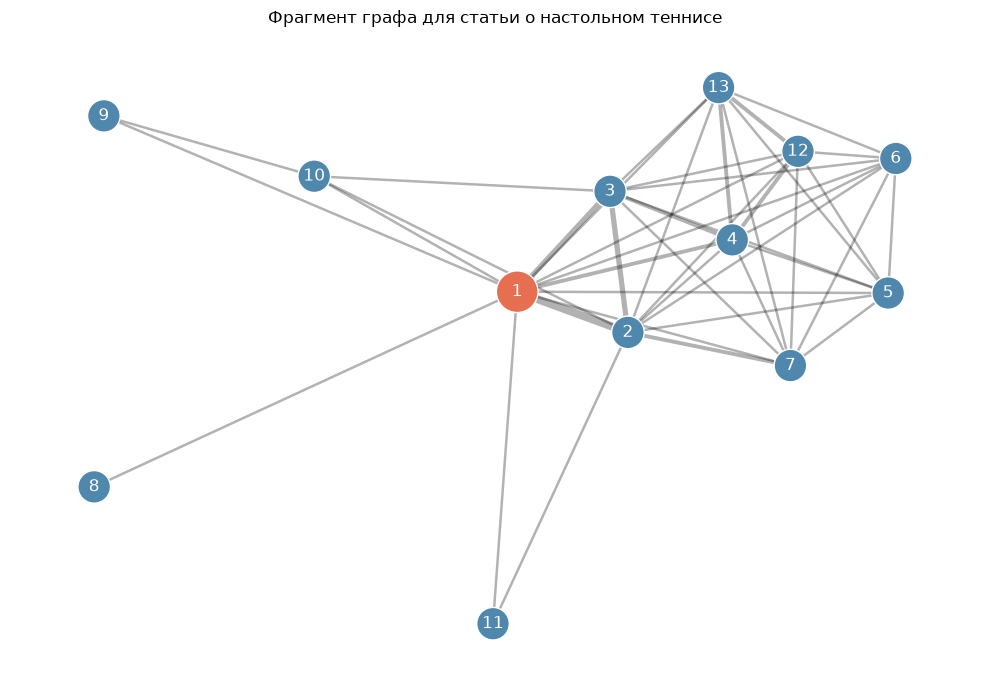

1  | Sport Task: Fine Grained Action Detection and Classification of Table Tennis Strokes from Videos for MediaEval 2022
2  | Sports Video: Fine-Grained Action Detection and Classification of Table Tennis Strokes from Videos for MediaEval 2021
3  | P2ANet: A Dataset and Benchmark for Dense Action Detection from Table Tennis Match Broadcasting Videos
4  | TT3D: Table Tennis 3D Reconstruction
5  | Table Tennis Stroke Recognition Using Two-Dimensional Human Pose Estimation
6  | Table Tennis Stroke Detection and Recognition Using Ball Trajectory Data
7  | 3D Convolutional Networks for Action Recognition: Application to Sport Gesture Recognition
8  | Decoupling Video and Human Motion: Towards Practical Event Detection in Athlete Recordings
9  | Sports Video Analysis on Large-Scale Data
10 | SkillSpotter: Pose-Aware Multi-View Skilled Action Detection and Grading in Ego-Exo Videos
11 | Feature Combination Meets Attention: Baidu Soccer Embeddings and Transformer based Temporal Detection
12 | 

In [29]:
source_index = int(df.index[df["arxiv_id"].eq("2301.13576")][0])
nearby = sorted(
    P.neighbors(source_index),
    key=lambda index: (-P[source_index][index]["weight"],
                       -P[source_index][index]["cosine"], df.at[index, "title"]),
)[:12]
shown_nodes = [source_index, *nearby]
shown = P.subgraph(shown_nodes).copy()
layout = nx.spring_layout(shown, seed=SEED, weight="weight", k=0.8)
labels = {node: str(number) for number, node in enumerate(shown_nodes, 1)}
fig, ax = plt.subplots(figsize=(10, 7))
nx.draw_networkx_edges(
    shown, layout, ax=ax, alpha=0.3,
    width=[0.8 + shown[u][v]["weight"] for u, v in shown.edges()],
)
nx.draw_networkx_nodes(
    shown, layout, ax=ax,
    node_size=[900 if node == source_index else 550 for node in shown],
    node_color=["#e76f51" if node == source_index else "#4f87ad" for node in shown],
    edgecolors="white",
)
nx.draw_networkx_labels(shown, layout, labels=labels, ax=ax, font_color="white")
ax.set_title("Фрагмент графа для статьи о настольном теннисе")
ax.axis("off")
plt.tight_layout()
plt.show()
for node, number in labels.items():
    print(f"{number:2s} | {df.at[node, 'title']}")


исходная статья 1 сильнее всего связана с работой 2: у них пять общих тегов.
Соседи относятся к настольному теннису или используют общие методы анализа видео.
Номера обозначают вершины, а не порядок близости.


## Поиск по графу

Стоимость ребра: `1 / (вес × (1 + cosine))`. Алгоритм Дейкстры находит
ближайшие публикации и показывает маршрут, число переходов и общие теги.
Параметр `min_similarity` задаёт минимум общих тегов на ребре.


In [30]:
def validate_search_parameters(top_n, min_similarity):
    for name, value in [("top_n", top_n), ("min_similarity", min_similarity)]:
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{name} должен быть положительным целым числом")


def find_publications(query):
    query = str(query).strip()
    if not query:
        return df.iloc[0:0]

    folded = query.casefold()
    id_query = re.sub(r"^https?://(?:export\.)?arxiv\.org/(?:abs|pdf)/", "", query)
    id_query = re.sub(r"\.pdf$", "", id_query.split("?")[0].rstrip("/"))
    id_query = re.sub(r"v\d+$", "", id_query).casefold()
    exact_mask = (
        df["title"].str.casefold().eq(folded)
        | df["arxiv_id"].astype(str).str.casefold().eq(id_query)
    )
    exact = df[exact_mask]
    if not exact.empty:
        return exact

    return df[df["title"].str.contains(query, case=False, na=False, regex=False)]


def nearest_publications(paper_index, top_n=5, min_similarity=1):
    validate_search_parameters(top_n, min_similarity)
    search_graph = nx.edge_subgraph(
        P,
        [(u, v) for u, v, edge in P.edges(data=True) if edge["weight"] >= min_similarity],
    ).copy()
    search_graph.add_nodes_from(P.nodes(data=True))
    distances, paths = nx.single_source_dijkstra(search_graph, paper_index, weight="distance")

    neighbors = []
    for neighbor, graph_distance in distances.items():
        if neighbor == paper_index:
            continue
        path = paths[neighbor]
        direct_edge = P.get_edge_data(paper_index, neighbor)
        neighbors.append({
            "index": int(neighbor),
            "title": df.at[neighbor, "title"],
            "graph_distance": float(graph_distance),
            "hops": len(path) - 1,
            "path": [df.at[node, "title"] for node in path],
            "direct_weight": int(direct_edge["weight"]) if direct_edge else 0,
            "direct_keywords": direct_edge["keywords"] if direct_edge else [],
            "direct_cosine": float(direct_edge["cosine"]) if direct_edge else 0.0,
            "direct_allowed": bool(direct_edge and direct_edge["weight"] >= min_similarity),
            "direct_distance": float(direct_edge["distance"]) if direct_edge else None,
            "url": df.at[neighbor, "url"],
        })
    return sorted(
        neighbors,
        key=lambda item: (item["graph_distance"], item["hops"], -item["direct_weight"], item["title"]),
    )[:top_n]


def search_papers(query, top_n=5, min_similarity=1, selected_index=None, verbose=True):
    validate_search_parameters(top_n, min_similarity)
    matches = find_publications(query)
    if matches.empty:
        result = {"status": "not_found", "query": query, "candidates": [], "neighbors": []}
        if verbose:
            print("публикации не найдены")
        return result

    if len(matches) > 1 and selected_index is None:
        candidates = [
            {"index": int(index), "paper_id": row["arxiv_id"], "title": row["title"]}
            for index, row in matches.iterrows()
        ]
        result = {"status": "ambiguous", "query": query, "candidates": candidates, "neighbors": []}
        if verbose:
            print("несколько совпадений, задайте selected_index:")
            for candidate in candidates:
                print(candidate["index"], "-", candidate["title"])
        return result

    if selected_index is None:
        paper_index = int(matches.index[0])
    else:
        if isinstance(selected_index, (bool, np.bool_)) or not isinstance(selected_index, (int, np.integer)):
            raise ValueError("selected_index должен быть целым индексом публикации")
        if selected_index not in matches.index:
            raise ValueError("selected_index отсутствует среди найденных публикаций")
        paper_index = int(selected_index)

    neighbors = nearest_publications(paper_index, top_n=top_n, min_similarity=min_similarity)
    status = "ok" if neighbors else "no_neighbors"
    result = {
        "status": status,
        "query": query,
        "source_index": paper_index,
        "source_title": df.at[paper_index, "title"],
        "neighbors": neighbors,
    }

    if verbose:
        print("статья:", result["source_title"])
        if not neighbors:
            print("связанные публикации не найдены")
        for neighbor in neighbors:
            print("\n", neighbor["title"])
            print("расстояние:", round(neighbor["graph_distance"], 4),
                  "| переходов:", neighbor["hops"])
            if neighbor["hops"] == 1:
                print("теги:", neighbor["direct_keywords"],
                      "| вес:", neighbor["direct_weight"],
                      "| cosine:", round(neighbor["direct_cosine"], 3))
            else:
                print("маршрут:", " → ".join(neighbor["path"]))
    return result

путь может проходить через другие статьи: несколько сильных связей иногда
дают меньшее расстояние, чем одна слабая. Поэтому в выдаче показаны число
переходов и маршрут. Порог общих тегов применяется к каждому ребру пути.


## Проверка реализации поиска

Проверяются связи графа, вес рёбер, маршруты и обработка запросов.


In [31]:
assert len(df) >= 300 and df["arxiv_id"].is_unique
assert df["published"].dt.year.min() >= 2020
assert df["keywords"].map(bool).all()
assert G.number_of_nodes() > 0 and P.number_of_nodes() == len(df)
assert nx.number_of_selfloops(G) == nx.number_of_selfloops(P) == 0

for first, second, edge in P.edges(data=True):
    shared = set(df.at[first, "keywords"]) & set(df.at[second, "keywords"])
    assert edge["weight"] == len(shared)
    assert set(edge["keywords"]) == shared
    assert abs(edge["distance"] - 1 / (len(shared) * (1 + edge["cosine"]))) < 1e-12
for first, second in combinations(df.index, 2):
    assert P.has_edge(first, second) == bool(
        set(df.at[first, "keywords"]) & set(df.at[second, "keywords"])
    )

example_id = df.at[0, "arxiv_id"]
assert find_publications(example_id).index.tolist() == [0]
assert find_publications(df.at[0, "url"] + "v1").index.tolist() == [0]
assert search_papers("   ", verbose=False)["status"] == "not_found"
assert search_papers("zzzz-no-such-publication", verbose=False)["status"] == "not_found"
assert search_papers("Table Tennis", verbose=False)["status"] == "ambiguous"
ambiguous = search_papers("Table Tennis", verbose=False)
chosen = ambiguous["candidates"][0]["index"]
assert search_papers("Table Tennis", selected_index=chosen,
                     verbose=False)["source_index"] == chosen
all_results = nearest_publications(0, top_n=len(df))
multihop = [item for item in all_results if item["hops"] >= 2]
assert multihop, "Многопереходный маршрут не найден"
assert all(nx.is_path(P, [int(df.index[df["title"].eq(title)][0])
                          for title in item["path"]]) for item in multihop[:5])
strong_results = nearest_publications(0, top_n=len(df), min_similarity=2)
for item in strong_results:
    ids = [int(df.index[df["title"].eq(title)][0]) for title in item["path"]]
    assert all(P[u][v]["weight"] >= 2 for u, v in zip(ids, ids[1:]))
for invalid in (0, -1, True, 1.5):
    try:
        search_papers(example_id, top_n=invalid, verbose=False)
    except ValueError:
        pass
    else:
        raise AssertionError("Недопустимый top_n принят")

print("проверки пройдены, пар:", len(df) * (len(df) - 1) // 2)


проверки пройдены, пар: 52975


## Примеры поиска

Приведены результаты для настольного тенниса, прыжков в воду, спринта,
бадминтона и ударных нагрузок.


In [32]:
for paper_id in ["2301.13576", "2609.19354", "2409.10175", "2502.21085", "2502.15405"]:
    result = search_papers(paper_id, verbose=False)
    print("\nстатья:", result["source_title"])
    for neighbor in result["neighbors"][:5]:
        tags = ", ".join(neighbor["direct_keywords"]) or "нет прямой связи"
        print(f"  {neighbor['title']} | d={neighbor['graph_distance']:.3f}"
              f" | переходов={neighbor['hops']} | теги: {tags}")



статья: Sport Task: Fine Grained Action Detection and Classification of Table Tennis Strokes from Videos for MediaEval 2022
  Sports Video: Fine-Grained Action Detection and Classification of Table Tennis Strokes from Videos for MediaEval 2021 | d=0.112 | переходов=1 | теги: action detection, mediaeval, table tennis, tennis stroke, untrimmed video
  P2ANet: A Dataset and Benchmark for Dense Action Detection from Table Tennis Match Broadcasting Videos | d=0.243 | переходов=1 | теги: action detection, table tennis, tennis match
  TT3D: Table Tennis 3D Reconstruction | d=0.425 | переходов=1 | теги: table tennis, tennis match
  3D Convolutional Networks for Action Recognition: Application to Sport Gesture Recognition | d=0.535 | переходов=2 | теги: table tennis
  Table Tennis Stroke Recognition Using Two-Dimensional Human Pose Estimation | d=0.716 | переходов=1 | теги: table tennis

статья: Can Vision-Language Models Judge Olympic Diving? From Reasoning to Scores in Zero-Shot Action Quali

общий вид спорта не гарантирует одну задачу: рядом с распознаванием ударов
встречаются реконструкция матча, отслеживание игроков и управление роботом.
Это ограничение поиска по общим тегам.


### Ручная оценка поиска

Проверяются первые пять результатов для пяти задач:

настольный теннис: обнаружение или распознавание ударов;
прыжки в воду: оценка качества спортивного действия, другой вид спорта допустим;
спринт: видеоанализ бега и его биомеханики;
бадминтон: распознавание ударов;
ударные нагрузки: кинематика ударов головы и травмы в контактном спорте.

Общий метод без нужной задачи не считается подходящим. Для каждой пары
сохраняются оценка 1 или 0 и короткая причина по названию и аннотации.


In [33]:
judgments = {
    "2301.13576": {
        "2112.11384": (1, "обнаружение и классификация ударов"),
        "2207.12730": (1, "набор матчей с разметкой действий"),
        "2504.10035": (0, "3D-реконструкция, а не распознавание ударов"),
        "2204.08460": (1, "классификация ударов по видео"),
        "2104.09907": (1, "распознавание ударов по позе"),
        "2302.09657": (1, "распознавание ударов по траектории мяча"),
        "2004.09776": (0, "обнаружение событий без задачи классификации ударов"),
        "2208.04897": (0, "общий анализ спортивного видео"),
    },
    "2609.19354": {
        "2604.08294": (1, "оценка качества действий с помощью VLM"),
        "2303.09097": (1, "оценка исполнения в фигурном катании"),
        "2410.14161": (1, "оценка качества спортивных упражнений"),
        "2511.10250": (1, "оценка качества исполнения в лыжной акробатике"),
        "2204.03646": (1, "оценка качества прыжков в воду"),
        "2511.21653": (1, "оценка качества длинных спортивных действий"),
        "2507.21945": (1, "оценка качества художественных спортивных действий"),
        "2503.23911": (1, "объяснимая оценка качества спортивного действия"),
    },
    "2409.10175": {
        "2505.04713": (1, "видеоанализ биомеханики бега"),
        "2608.19480": (1, "безмаркерное отслеживание движений бегуна"),
        "2204.08805": (1, "анализ поз и суставных углов при беге"),
        "2307.12183": (1, "оценка движений бегуна по видео"),
        "2507.03016": (1, "оценка длины шага по видео"),
        "2605.28549": (0, "управление бегом робота"),
        "2602.22941": (0, "гребля на каноэ, а не бег"),
        "2010.06449": (0, "общий обзор оценки позы без отдельной задачи бега"),
        "2001.05613": (0, "общий захват движений, без анализа биомеханики бега"),
        "2104.11452": (0, "общий захват спортивных движений, без отдельной оценки бега"),
    },
    "2502.21085": {
        "2308.12199": (0, "отслеживание перемещений игроков"),
        "2509.05334": (0, "скорость волана, а не распознавание типа удара"),
        "2403.08956": (0, "биомеханика и рекомендации, а не классификация ударов"),
        "2403.12385": (1, "набор данных для распознавания действий в бадминтоне"),
        "2609.31840": (0, "управление ударами робота"),
    },
    "2502.15405": {
        "2502.14710": (1, "измерение ускорений головы в американском футболе"),
        "2108.08763": (1, "сравнение ускорений головы при спортивных ударах"),
        "2010.08485": (1, "сбор данных об ударах головы у футболистов"),
        "2108.08797": (1, "обнаружение ударов головы в американском футболе"),
        "2102.05020": (1, "кинематика ударов и риск травмы мозга"),
        "2104.09082": (1, "классификация спортивных ударов по кинематике"),
        "2102.05728": (1, "кинематика ударов головы в американском футболе"),
        "2010.08527": (1, "оценка деформации мозга при спортивных ударах"),
        "2409.08177": (1, "оценка положения и силы удара по кинематике головы"),
    },
}
precision_at_five = {}
evaluation_rows = []
for source_id, labels in judgments.items():
    results = search_papers(source_id, top_n=5, verbose=False)["neighbors"]
    if len(results) != 5:
        raise ValueError("для оценки нужны пять результатов")
    hits = []
    print("\nзапрос:", source_id)
    for item in results:
        paper_id = df.at[item["index"], "arxiv_id"]
        if paper_id not in labels:
            raise ValueError(f"нет ручной оценки пары {source_id}, {paper_id}")
        hit, reason = labels[paper_id]
        assert hit in (0, 1) and reason
        hits.append(hit)
        evaluation_rows.append((source_id, paper_id, hit, reason))
        print(f"{paper_id}: {hit} | {reason}")
    precision_at_five[source_id] = sum(hits) / 5
    print(f"Precision@5: {precision_at_five[source_id]:.2f}")
print("\nсреднее Precision@5:", round(np.mean(list(precision_at_five.values())), 3))



запрос: 2301.13576
2112.11384: 1 | обнаружение и классификация ударов
2207.12730: 1 | набор матчей с разметкой действий
2504.10035: 0 | 3D-реконструкция, а не распознавание ударов
2204.08460: 1 | классификация ударов по видео
2104.09907: 1 | распознавание ударов по позе
Precision@5: 0.80

запрос: 2609.19354
2604.08294: 1 | оценка качества действий с помощью VLM
2303.09097: 1 | оценка исполнения в фигурном катании
2410.14161: 1 | оценка качества спортивных упражнений
2511.10250: 1 | оценка качества исполнения в лыжной акробатике
2204.03646: 1 | оценка качества прыжков в воду
Precision@5: 1.00

запрос: 2409.10175
2505.04713: 1 | видеоанализ биомеханики бега
2608.19480: 1 | безмаркерное отслеживание движений бегуна
2605.28549: 0 | управление бегом робота
2204.08805: 1 | анализ поз и суставных углов при беге
2010.06449: 0 | общий обзор оценки позы без отдельной задачи бега
Precision@5: 0.60

запрос: 2502.21085
2308.12199: 0 | отслеживание перемещений игроков
2509.05334: 0 | скорость волан

средняя Precision@5 по пяти запросам равна 0,720. Для оценки качества действий
и ударных нагрузок найдены подходящие работы, а в бадминтоне смешиваются разные задачи.



## Собственный запрос


In [34]:
USER_QUERY = "2301.13576"
TOP_N = 5
MIN_SIMILARITY = 1
SELECTED_INDEX = None

user_result = search_papers(USER_QUERY, top_n=TOP_N, min_similarity=MIN_SIMILARITY,
                            selected_index=SELECTED_INDEX)


статья: Sport Task: Fine Grained Action Detection and Classification of Table Tennis Strokes from Videos for MediaEval 2022

 Sports Video: Fine-Grained Action Detection and Classification of Table Tennis Strokes from Videos for MediaEval 2021
расстояние: 0.1123 | переходов: 1
теги: ['action detection', 'mediaeval', 'table tennis', 'tennis stroke', 'untrimmed video'] | вес: 5 | cosine: 0.781

 P2ANet: A Dataset and Benchmark for Dense Action Detection from Table Tennis Match Broadcasting Videos
расстояние: 0.2425 | переходов: 1
теги: ['action detection', 'table tennis', 'tennis match'] | вес: 3 | cosine: 0.374

 TT3D: Table Tennis 3D Reconstruction
расстояние: 0.4254 | переходов: 1
теги: ['table tennis', 'tennis match'] | вес: 2 | cosine: 0.175

 3D Convolutional Networks for Action Recognition: Application to Sport Gesture Recognition
расстояние: 0.5353 | переходов: 2
маршрут: Sport Task: Fine Grained Action Detection and Classification of Table Tennis Strokes from Videos for MediaEva

## вывод

в выборке 326 статей. Частоты слов близки к закону Ципфа на рангах 10-1000.
Louvain: число групп 20, модулярность 0,530. По четырём центральностям
лидирует `human pose estimation`.

поиск использует общие теги и сходство текстов. Средняя Precision@5 по пяти запросам
равна 0,720. Общий вид спорта не всегда означает совпадение исследовательской задачи.
